 2. In a new .ipynb/.py file called **uva_analysis**, analyze foreign giving to UVA. Compare UVA to appropriate peer institutions and the market overall.
Propose a strategy for finding new sources of foreign money and provide a quantitative analysis.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

df = pd.read_csv('ForeignGifts_edu.csv',low_memory=False)
df.head()

,ID,OPEID,Institution Name,City,State,Foreign Gift Received Date,Foreign Gift Amount,Gift Type,Country of Giftor,Giftor Name
0,1,102000,Jacksonville State University,Jacksonville,AL,43738,250000,Monetary Gift,CHINA,NaN
1,2,104700,Troy University,Troy,AL,43592,463657,Contract,CHINA,Confucius Institute Headquarters
2,3,105100,University of Alabama,Tuscaloosa,AL,43466,3649107,Contract,ENGLAND,Springer Nature Customer Service Ce
3,4,105100,University of Alabama,Tuscaloosa,AL,43472,1000,Contract,SAUDI ARABIA,Saudi Arabia Education Mission
4,5,105100,University of Alabama,Tuscaloosa,AL,43479,49476,Contract,SAUDI ARABIA,Saudi Arabia Education Mission


In [14]:
top_20_countries = (
    df.groupby("Country of Giftor")["Foreign Gift Amount"]
    .sum()
    .sort_values(ascending=False)
    .head(20)
)

top_20_countries

Country of Giftor
QATAR                   2706240869
ENGLAND                 1464906771
CHINA                   1237952112
SAUDI ARABIA            1065205930
BERMUDA                  899593972
CANADA                   898160656
HONG KONG                887402529
JAPAN                    655954776
SWITZERLAND              619899445
INDIA                    539556490
GERMANY                  442475605
UNITED ARAB EMIRATES     431396357
FRANCE                   405839396
SINGAPORE                401157692
AUSTRALIA                248409202
KUWAIT                   234106321
DENMARK                  173956102
THE NETHERLANDS          166062836
BRAZIL                   158757039
SWEDEN                   157650306
Name: Foreign Gift Amount, dtype: int64

In [15]:
countries_to_uva = df[
    (df["Country of Giftor"].isin(top_20_countries.index)) &
    (df["Institution Name"] == "University of Virginia")
]["Country of Giftor"].nunique()

print(f"{countries_to_uva} of the top 20 gift-giving countries contribute to UVA.")

8 of the top 20 gift-giving countries contribute to UVA.


In [16]:
top_20_giftors = (
    df.groupby("Giftor Name")["Foreign Gift Amount"]
    .sum()
    .sort_values(ascending=False)
    .head(20)
)

top_20_giftors

Giftor Name
Qatar Foundation                       1166503744
Qatar Foundation/Qatar National Res     796197000
Qatar Foundation for Education          373945215
Anonymous                               338793629
Saudi Arabian Cultural Mission          275221475
HCL                                     190000000
Church of Jesus Christ of LDS           185203715
Emirates Institute for Advanced Sc      170641244
QIC                                     148355497
Anonymous #9                             96334996
Qatar National Research Fund             79021705
Government of Saudi Arabia               75192434
Contracting Party                        69996984
CMKL University                          67700000
Royal Embassy of Saudi Arabia            67062486
Sanofi-Aventis Recerche                  62106706
Saudi Arabia                             59450098
Sanofi-Aventis Recherche                 58520202
Skolkovo Foundation                      51500000
Stavros S. Niarchos Foundation        

In [17]:
foundations_to_uva = df[
    (df["Giftor Name"].isin(top_20_giftors.index)) &
    (df["Institution Name"] == "University of Virginia")
]["Giftor Name"].nunique()

print(f"{foundations_to_uva} of the top 20 gift-giving countries contribute to UVA.")

0 of the top 20 gift-giving countries contribute to UVA.


In [18]:
uva = df[df["Institution Name"] == "University of Virginia"]

uva_country_totals = (
    uva.groupby("Country of Giftor")["Foreign Gift Amount"]
    .sum()
    .sort_values(ascending=False)
)

uva_country_totals

Country of Giftor
BANGLADESH         4228589
SWEDEN             4007552
TANZANIA           2776447
SWITZERLAND        2000000
ENGLAND            1950666
GUERNSEY           1500000
FINLAND            1008384
BERMUDA             900000
KOREA               862787
SINGAPORE           805000
THE NETHERLANDS     725670
ISRAEL              623655
RWANDA              284135
JAPAN               265970
FRANCE              250383
Name: Foreign Gift Amount, dtype: int64

In [19]:
country_university_totals = (
    df.groupby(["Country of Giftor", "Institution Name"])["Foreign Gift Amount"]
    .sum()
    .sort_values(ascending=False)
)

country_university_totals.head(10)

Country of Giftor     Institution Name              
QATAR                 Cornell University                1018473315
BERMUDA               Carnegie Mellon University         750000000
QATAR                 Texas A&M University               504099350
                      Carnegie Mellon University         425410702
                      Georgetown University              327128310
                      Northwestern University            311148564
CANADA                Brigham Young University           259927758
UNITED ARAB EMIRATES  University of Colorado Boulder     219734835
ENGLAND               Harvard University                 188328288
HONG KONG             Yale University                    161131218
Name: Foreign Gift Amount, dtype: int64

In [21]:
top_20_institutions = (
    df.groupby("Institution Name")["Foreign Gift Amount"]
    .sum()
    .sort_values(ascending=False)
    .head(20)
)

In [22]:
top_20_data = df[
    (df["Country of Giftor"].isin(top_20_countries.index)) &
    (df["Institution Name"].isin(top_20_institutions.index))
]

In [23]:
pd.crosstab(
    top_20_data["Country of Giftor"],
    top_20_data["Institution Name"]
)

Institution Name,Brigham Young University,Carnegie Mellon University,Columbia University in the City of New York,Cornell University,Duke University,Georgetown University,Harvard University,Johns Hopkins University,Massachusetts Institute of Technology,Northwestern University,Stanford University,Texas A&M University,"University of California, Berkeley",University of Chicago (The),University of Colorado Boulder,University of Michigan - Ann Arbor,University of Pennsylvania,University of Southern California,University of Texas MD Anderson Cancer Center,Yale University
Country of Giftor,,,,,,,,,,,,,,,,,,,,
AUSTRALIA,0,2,16,5,2,0,8,9,6,0,10,0,3,5,1,7,1,7,2,5
BERMUDA,0,10,6,3,0,0,6,5,5,0,0,0,4,0,0,1,1,0,0,2
BRAZIL,1,0,38,3,0,1,8,5,21,0,7,0,1,5,5,2,3,0,13,3
CANADA,21,4,22,37,6,0,20,31,15,12,102,7,14,10,22,39,23,23,2,13
CHINA,8,16,102,48,3,10,23,20,48,24,134,6,47,53,7,83,133,43,14,89
DENMARK,0,0,11,4,1,0,10,9,14,6,1,0,6,4,3,23,5,1,5,7
ENGLAND,16,9,164,27,20,13,23,38,37,14,42,3,34,63,40,85,129,27,33,96
FRANCE,0,1,35,25,16,11,17,28,14,14,34,0,17,36,4,34,27,10,4,34
GERMANY,1,2,53,32,5,2,14,22,11,0,17,0,38,0,0,44,24,12,13,36


In [24]:
uva_countries = df[
    df["Institution Name"] == "University of Virginia"
]["Country of Giftor"].unique()

top_20_no_uva = top_20_countries[
    ~top_20_countries.index.isin(uva_countries)
]

top_20_no_uva

Country of Giftor
QATAR                   2706240869
CHINA                   1237952112
SAUDI ARABIA            1065205930
CANADA                   898160656
HONG KONG                887402529
INDIA                    539556490
GERMANY                  442475605
UNITED ARAB EMIRATES     431396357
AUSTRALIA                248409202
KUWAIT                   234106321
DENMARK                  173956102
BRAZIL                   158757039
Name: Foreign Gift Amount, dtype: int64

In [25]:
potential_giftors = df[
    df["Country of Giftor"].isin(top_20_no_uva.index)
]

potential_giftors[[
    "Giftor Name",
    "Country of Giftor",
    "Foreign Gift Amount"
]]

,Giftor Name,Country of Giftor,Foreign Gift Amount
0,NaN,CHINA,250000
1,Confucius Institute Headquarters,CHINA,463657
3,Saudi Arabia Education Mission,SAUDI ARABIA,1000
4,Saudi Arabia Education Mission,SAUDI ARABIA,49476
5,Kuwait-Embassy of the State,KUWAIT,30231
...,...,...,...
28209,Light Year Holdings LTD,HONG KONG,150000
28210,Shao Ming Lo Foundation LTD,HONG KONG,400000
28211,Shao Ming Lo Foundation LTD,HONG KONG,350000
28212,Minglo Shao,HONG KONG,400000


In [26]:
potential_giftors = (
    df[
        df["Country of Giftor"].isin(top_20_no_uva.index)
    ]
    .groupby(["Giftor Name", "Country of Giftor"])["Foreign Gift Amount"]
    .sum()
    .sort_values(ascending=False)
)

potential_giftors.head(20)

Giftor Name                          Country of Giftor   
Qatar Foundation                     QATAR                   1165905872
Qatar Foundation/Qatar National Res  QATAR                    796197000
Qatar Foundation for Education       QATAR                    373945215
Saudi Arabian Cultural Mission       SAUDI ARABIA             274767659
HCL                                  INDIA                    190000000
Church of Jesus Christ of LDS        CANADA                   185203715
Emirates Institute for Advanced Sc   UNITED ARAB EMIRATES     170641244
QIC                                  AUSTRALIA                148355497
Anonymous #9                         HONG KONG                 95023463
Qatar National Research Fund         QATAR                     79021705
Government of Saudi Arabia           SAUDI ARABIA              75192434
Royal Embassy of Saudi Arabia        SAUDI ARABIA              67062486
Anonymous                            CHINA                     62260714
Saudi 

In [27]:
uva_countries = df[
    df["Institution Name"] == "University of Virginia"
]["Country of Giftor"].unique()

top_3_no_uva = top_20_countries[
    ~top_20_countries.index.isin(uva_countries)
].head(3)

top_3_no_uva

Country of Giftor
QATAR           2706240869
CHINA           1237952112
SAUDI ARABIA    1065205930
Name: Foreign Gift Amount, dtype: int64

In [28]:
potential_giftors = (
    df[df["Country of Giftor"].isin(top_3_no_uva.index)]
    .groupby(["Country of Giftor", "Giftor Name"])["Foreign Gift Amount"]
    .sum()
    .sort_values(ascending=False)
)

potential_giftors.head(20)

Country of Giftor  Giftor Name                        
QATAR              Qatar Foundation                       1165905872
                   Qatar Foundation/Qatar National Res     796197000
                   Qatar Foundation for Education          373945215
SAUDI ARABIA       Saudi Arabian Cultural Mission          274767659
QATAR              Qatar National Research Fund             79021705
SAUDI ARABIA       Government of Saudi Arabia               75192434
                   Royal Embassy of Saudi Arabia            67062486
CHINA              Anonymous                                62260714
SAUDI ARABIA       Saudi Arabia                             59450098
                   Mr. Mohammed A. Jameel                   43000000
CHINA              Wenzhou-Kean University                  39148779
                   BEG Holdings, LP                         35300000
SAUDI ARABIA       Jameel. Mohammed, Abdul                  30000000
                   Aramco Services Company      

In [29]:
uva_country_totals.head(1)

Country of Giftor
BANGLADESH    4228589
Name: Foreign Gift Amount, dtype: int64

In [30]:
biggest_uva_country = uva_country_totals.index[0]

giftors_not_uva = (
    df[
        (df["Country of Giftor"] == biggest_uva_country) &
        (df["Institution Name"] != "University of Virginia")
    ]
    .groupby("Giftor Name")["Foreign Gift Amount"]
    .sum()
    .sort_values(ascending=False)
)

giftors_not_uva.head(10)

Giftor Name
World Organization fr Animal Health    514025
Name: Foreign Gift Amount, dtype: int64

In [36]:
bangladesh_uva = (
    df[
        (df["Country of Giftor"] == "BANGLADESH") &
        (df["Institution Name"] == "University of Virginia")
    ]
    .groupby("Giftor Name")["Foreign Gift Amount"]
    .sum()
    .sort_values(ascending=False)
)

bangladesh_uva.head(10)

Giftor Name
Intrnl Centre Diarrheal Disease        1382896
Intnl Centre for Diarrhoeal Disease     919857
International Centre for Diarrhoeal     919518
Intl. Cntr for Diarrihoeal Disease      696317
Intl Ctr for Diarrhoeal Disease         310001
Name: Foreign Gift Amount, dtype: int64

In [33]:
bangladesh_uva.head(1)

Series([], Name: Foreign Gift Amount, dtype: int64)

In [35]:
df[df["Country of Giftor"].str.contains("Bangladesh", case=False, na=False)]["Country of Giftor"].unique()

array(['BANGLADESH'], dtype=object)

In [34]:
top_giftor = bangladesh_uva.index[0]

df[df["Giftor Name"] == top_giftor].groupby(
    "Institution Name"
)["Foreign Gift Amount"].sum().sort_values(ascending=False)

IndexError: index 0 is out of bounds for axis 0 with size 0

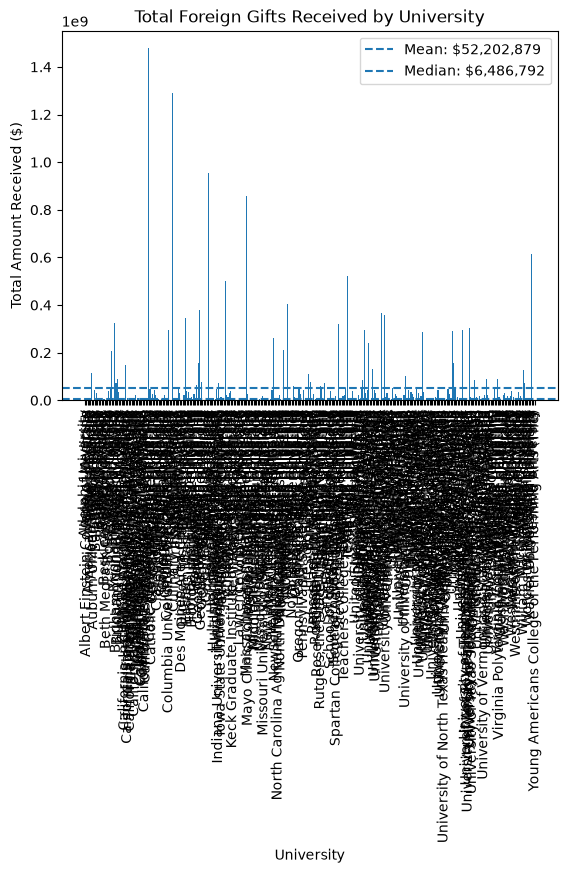

In [7]:
university_totals = df.groupby("Institution Name")["Foreign Gift Amount"].sum()

mean = university_totals.mean()
median = university_totals.median()

plt.bar(university_totals.index, university_totals)

plt.axhline(mean, linestyle="--", label=f"Mean: ${mean:,.0f}")
plt.axhline(median, linestyle="--", label=f"Median: ${median:,.0f}")

plt.xlabel("University")
plt.ylabel("Total Amount Received ($)")
plt.title("Total Foreign Gifts Received by University")

plt.xticks(rotation=90)

plt.legend()

plt.show()